In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from pptx import Presentation
from pptx.util import Inches, Pt
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("job_market_india.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (835, 6)


,Job Title,Location,Salary,Monthly Salary,Locality,State
0,Robotics / STEM Trainer,"Indore, Madhya Pradesh","₹1,80,000 - ₹3,60,000 a year",270000.0,NaN,Madhya Pradesh
1,HTML Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
2,Java Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
3,"Teachers - Pre-Primary and Primary (English, M...","Pulivendla, Andhra Pradesh","₹20,000 - ₹30,000 a month",25000.0,NaN,Andhra Pradesh
4,College Student,Remote,"₹15,000 - ₹20,000 a month",17500.0,Remote,Remote


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Column Names:
['Job Title', 'Location', 'Salary', 'Monthly Salary', 'Locality', 'State']

Missing Values:
Job Title           0
Location            0
Salary              0
Monthly Salary    338
Locality          581
State               0
dtype: int64

Duplicate Rows: 5

Data Types:
Job Title          object
Location           object
Salary             object
Monthly Salary    float64
Locality           object
State              object
dtype: object


In [5]:
print("Salary Format Distribution:")

print("Annual Salary:",
      df["Salary"].str.contains("a year", case=False, na=False).sum())

print("Monthly Salary:",
      df["Salary"].str.contains("a month", case=False, na=False).sum())

print("Daily Salary:",
      df["Salary"].str.contains("a day", case=False, na=False).sum())

print("Not Specified:",
      df["Salary"].str.contains("Not specified", case=False, na=False).sum())

Salary Format Distribution:
Annual Salary: 74
Monthly Salary: 516
Daily Salary: 4
Not Specified: 237


In [6]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)
print("Duplicates Removed:", len(df) - len(df_clean))
print("Remaining Duplicates:", df_clean.duplicated().sum())

Original Dataset Shape: (835, 6)
Cleaned Dataset Shape: (830, 6)
Duplicates Removed: 5
Remaining Duplicates: 0


In [7]:
df_clean["Corrected Monthly Salary"] = df_clean["Monthly Salary"].copy()

annual_mask = df_clean["Salary"].str.contains(
    "a year", case=False, na=False
)

df_clean.loc[annual_mask, "Corrected Monthly Salary"] /= 12

# Exclude daily and other unsupported salary formats
monthly_mask = df_clean["Salary"].str.contains(
    "a month", case=False, na=False
)

df_clean.loc[
    ~(annual_mask | monthly_mask),
    "Corrected Monthly Salary"
] = np.nan

print("Salary correction completed!")
print("Valid Salary Records:",
      df_clean["Corrected Monthly Salary"].notna().sum())

print("Missing Salary Records:",
      df_clean["Corrected Monthly Salary"].isna().sum())

display(df_clean[
    ["Salary", "Monthly Salary", "Corrected Monthly Salary"]
].head(10))

Salary correction completed!
Valid Salary Records: 492
Missing Salary Records: 338


,Salary,Monthly Salary,Corrected Monthly Salary
0,"₹1,80,000 - ₹3,60,000 a year",270000.0,22500.0
1,Not specified,NaN,NaN
2,Not specified,NaN,NaN
3,"₹20,000 - ₹30,000 a month",25000.0,25000.0
4,"₹15,000 - ₹20,000 a month",17500.0,17500.0
5,Not specified,NaN,NaN
6,Not specified,NaN,NaN
7,Not specified,NaN,NaN
8,"₹14,678 - ₹22,689 a month",18683.5,18683.5
9,"From ₹12,800 a month",NaN,NaN


In [8]:
total_jobs = len(df_clean)

valid_salary = df_clean["Corrected Monthly Salary"].notna().sum()

avg_salary = df_clean["Corrected Monthly Salary"].mean()

median_salary = df_clean["Corrected Monthly Salary"].median()

remote_jobs = df_clean["State"].str.lower().eq("remote").sum()

remote_percentage = (remote_jobs / total_jobs) * 100

missing_salary_percentage = (
    df_clean["Corrected Monthly Salary"].isna().mean() * 100
)

print("===== EDA Summary =====")
print("Total Job Listings:", total_jobs)
print("Valid Salary Records:", valid_salary)
print(f"Average Monthly Salary: ₹{avg_salary:,.2f}")
print(f"Median Monthly Salary: ₹{median_salary:,.2f}")
print("Remote Jobs:", remote_jobs)
print(f"Remote Jobs Percentage: {remote_percentage:.2f}%")
print(f"Missing Salary Percentage: {missing_salary_percentage:.2f}%")

===== EDA Summary =====
Total Job Listings: 830
Valid Salary Records: 492
Average Monthly Salary: ₹22,850.86
Median Monthly Salary: ₹18,500.00
Remote Jobs: 89
Remote Jobs Percentage: 10.72%
Missing Salary Percentage: 40.72%


In [9]:
top_states = df_clean["State"].value_counts().head(5)

top_jobs = df_clean["Job Title"].value_counts().head(5)

insights = [
    f"The dataset contains {total_jobs} unique job listings.",

    f"{top_states.index[0]} has the highest number of listings "
    f"with {top_states.iloc[0]} jobs.",

    f"The average monthly salary is ₹{avg_salary:,.2f}, "
    f"while the median is ₹{median_salary:,.2f}.",

    f"Remote jobs account for {remote_percentage:.2f}% "
    f"of total listings.",

    f"{missing_salary_percentage:.2f}% of listings lack "
    f"usable salary information, limiting salary analysis."
]

print("===== Top 5 Business Insights =====\n")

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

print("\nTop 5 States:")
print(top_states)

print("\nTop 5 Job Titles:")
print(top_jobs)

===== Top 5 Business Insights =====

1. The dataset contains 830 unique job listings.
2. Kerala has the highest number of listings with 159 jobs.
3. The average monthly salary is ₹22,850.86, while the median is ₹18,500.00.
4. Remote jobs account for 10.72% of total listings.
5. 40.72% of listings lack usable salary information, limiting salary analysis.

Top 5 States:
State
Kerala         159
Tamil Nadu     148
Karnataka      104
Remote          89
Maharashtra     78
Name: count, dtype: int64

Top 5 Job Titles:
Job Title
Delivery Partner/Delivery Executive    9
Business Development Associate         8
Video Editor                           8
Trainee                                8
Management Trainee                     6
Name: count, dtype: int64


In [10]:
prompt = f"""
You are a professional business data analyst.

Write an approximately 200-word executive summary
based on the following job market insights:

{chr(10).join(insights)}

Include:
- Job market overview
- Geographic distribution
- Salary trends
- Remote work opportunities
- Data limitations
- Business recommendations

Use professional business language.
Do not invent statistics or unsupported facts.
Return only the executive summary.
"""

response = requests.post(
    "http://localhost:11434/api/generate",
    json={
        "model": "qwen2.5:3b",
        "prompt": prompt,
        "stream": False,
        "options": {"temperature": 0.2}
    },
    timeout=180
)

response.raise_for_status()

executive_summary = response.json()["response"].strip()

print("===== AI Executive Summary =====\n")
print(executive_summary)

print("\nWord Count:", len(executive_summary.split()))

===== AI Executive Summary =====

Executive Summary:

The job market landscape analyzed in this dataset reveals a significant geographic concentration in Kerala, with 159 unique job listings, representing the highest number of positions. The average monthly salary across all listings is ₹22,850.86, with a median of ₹18,500.00, indicating a balanced salary distribution. Remote work opportunities account for 10.72% of the total listings, offering flexibility to job seekers and employers alike. However, a substantial portion of listings (40.72%) lack usable salary information, which limits the analysis of salary trends and market competitiveness.

Despite these data limitations, the insights provided offer a comprehensive view of the job market dynamics. For businesses, these findings suggest a strong presence in Kerala, the potential for remote work to attract a broader talent pool, and the need to address the issue of salary information in job listings. Recommendations include enhancing

In [11]:
executive_summary = executive_summary.replace(
    "across all listings",
    "across 492 valid salary records"
)

executive_summary = executive_summary.replace(
    "indicating a balanced salary distribution",
    "with the mean exceeding the median"
)

executive_summary = executive_summary.replace(
    "tap into a growing market",
    "explore a market with a high concentration of listings"
)

print("===== Validated Executive Summary =====\n")
print(executive_summary)

print("\nWord Count:", len(executive_summary.split()))

===== Validated Executive Summary =====

Executive Summary:

The job market landscape analyzed in this dataset reveals a significant geographic concentration in Kerala, with 159 unique job listings, representing the highest number of positions. The average monthly salary across 492 valid salary records is ₹22,850.86, with a median of ₹18,500.00, with the mean exceeding the median. Remote work opportunities account for 10.72% of the total listings, offering flexibility to job seekers and employers alike. However, a substantial portion of listings (40.72%) lack usable salary information, which limits the analysis of salary trends and market competitiveness.

Despite these data limitations, the insights provided offer a comprehensive view of the job market dynamics. For businesses, these findings suggest a strong presence in Kerala, the potential for remote work to attract a broader talent pool, and the need to address the issue of salary information in job listings. Recommendations inclu

In [12]:
plt.figure(figsize=(10, 5))

top_states.sort_values().plot(
    kind="barh",
    color="#2563EB"
)

plt.title("Top 5 Locations by Job Listings")
plt.xlabel("Number of Job Listings")
plt.ylabel("Location")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "top_5_locations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


<Figure size 1000x500 with 1 Axes>

Chart saved successfully!


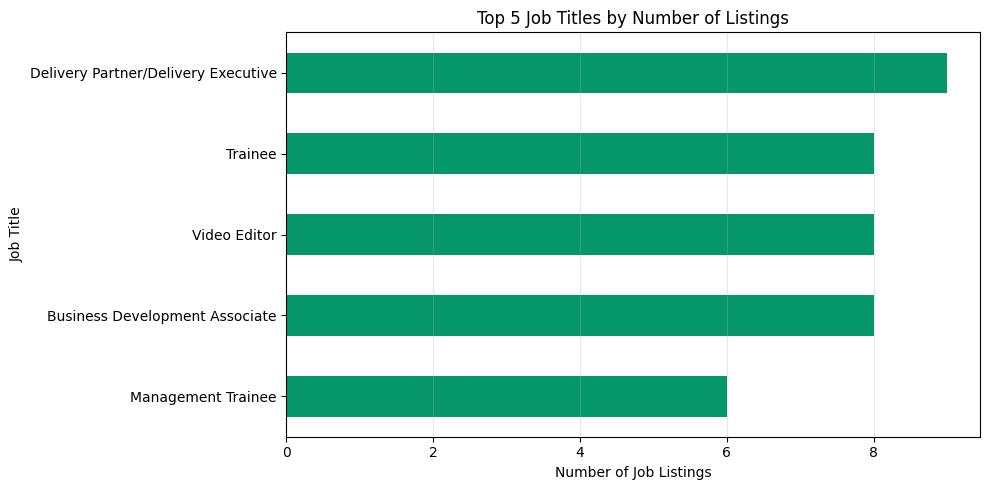

Job titles chart saved successfully!


In [13]:
plt.figure(figsize=(10, 5))

top_jobs.sort_values().plot(
    kind="barh",
    color="#059669"
)

plt.title("Top 5 Job Titles by Number of Listings")
plt.xlabel("Number of Job Listings")
plt.ylabel("Job Title")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "top_5_job_titles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Job titles chart saved successfully!")

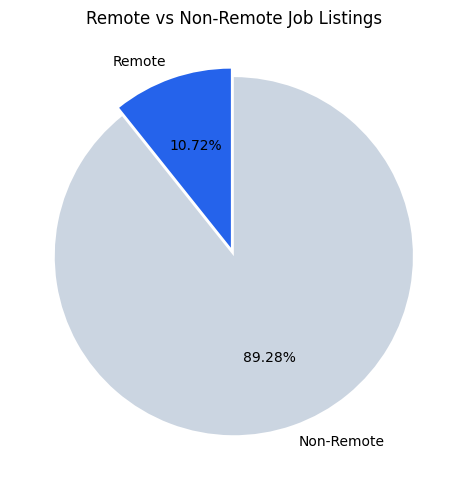

Remote work chart saved successfully!


In [14]:
work_distribution = [
    remote_jobs,
    total_jobs - remote_jobs
]

plt.figure(figsize=(7, 5))

plt.pie(
    work_distribution,
    labels=["Remote", "Non-Remote"],
    autopct="%1.2f%%",
    colors=["#2563EB", "#CBD5E1"],
    startangle=90,
    explode=[0.05, 0]
)

plt.title("Remote vs Non-Remote Job Listings")

plt.tight_layout()

plt.savefig(
    "remote_work_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Remote work chart saved successfully!")

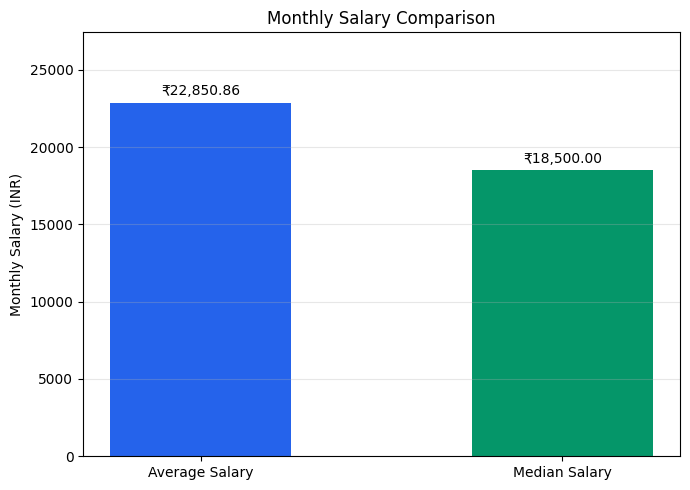

Salary comparison chart saved successfully!


In [15]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Average Salary", "Median Salary"],
    [avg_salary, median_salary],
    color=["#2563EB", "#059669"],
    width=0.5
)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 500,
        f"₹{value:,.2f}",
        ha="center"
    )

plt.title("Monthly Salary Comparison")
plt.ylabel("Monthly Salary (INR)")
plt.ylim(0, max(avg_salary, median_salary) * 1.2)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "salary_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Salary comparison chart saved successfully!")

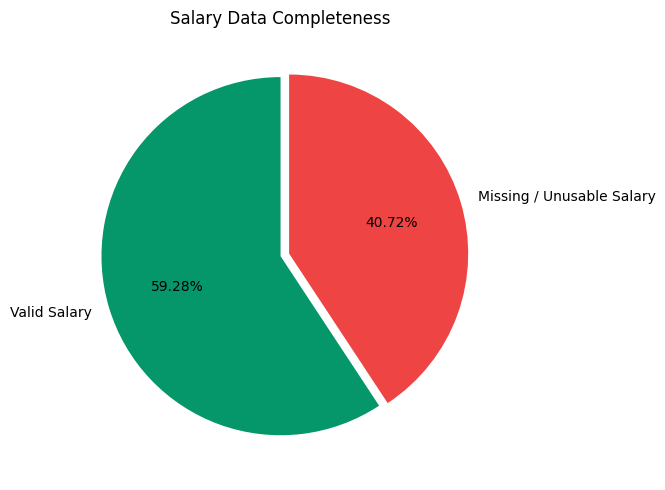

Salary data completeness chart saved successfully!


In [16]:
missing_salary = total_jobs - valid_salary

plt.figure(figsize=(7, 5))

plt.pie(
    [valid_salary, missing_salary],
    labels=["Valid Salary", "Missing / Unusable Salary"],
    autopct="%1.2f%%",
    colors=["#059669", "#EF4444"],
    startangle=90,
    explode=[0, 0.05]
)

plt.title("Salary Data Completeness")

plt.tight_layout()

plt.savefig(
    "salary_data_completeness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Salary data completeness chart saved successfully!")

In [17]:
from pptx.dml.color import RGBColor

prs = Presentation()

# Set widescreen slide dimensions (16:9)
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

# Create title slide
slide = prs.slides.add_slide(prs.slide_layouts[0])

slide.shapes.title.text = "Indian Job Market Analysis"

slide.placeholders[1].text = (
    "AI-Powered Executive Business Report\n"
    "Week 8 - Day 3 | Data Analyst Internship\n"
    "Cynaris Solutions Pvt. Ltd."
)

# Add executive summary to speaker notes
slide.notes_slide.notes_text_frame.text = executive_summary

print("PowerPoint initialized successfully!")
print("Title slide created!")
print("Executive summary added to speaker notes!")
print("Total Slides:", len(prs.slides))

PowerPoint initialized successfully!
Title slide created!
Executive summary added to speaker notes!
Total Slides: 1


In [18]:
def add_insight_slide(title, insight, chart_path):

    slide = prs.slides.add_slide(prs.slide_layouts[6])

    # Background
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(248, 250, 252)

    # Slide title
    title_box = slide.shapes.add_textbox(
        Inches(0.5), Inches(0.3),
        Inches(12.3), Inches(0.7)
    )

    title_frame = title_box.text_frame
    title_frame.text = title

    p = title_frame.paragraphs[0]
    p.font.size = Pt(30)
    p.font.bold = True
    p.font.color.rgb = RGBColor(30, 41, 59)

    # Business insight
    insight_box = slide.shapes.add_textbox(
        Inches(0.6), Inches(1.2),
        Inches(12.1), Inches(1.1)
    )

    insight_frame = insight_box.text_frame
    insight_frame.word_wrap = True
    insight_frame.text = insight

    p = insight_frame.paragraphs[0]
    p.font.size = Pt(20)
    p.font.color.rgb = RGBColor(51, 65, 85)

    # Insert chart
    if Path(chart_path).is_file():

        picture = slide.shapes.add_picture(
            chart_path,
            Inches(0),
            Inches(2.4),
            height=Inches(4.5)
        )

        if picture.width > Inches(12):
            ratio = Inches(12) / picture.width
            picture.width = Inches(12)
            picture.height = int(picture.height * ratio)

        picture.left = int(
            (prs.slide_width - picture.width) / 2
        )

    else:
        raise FileNotFoundError(chart_path)

    # Speaker notes
    slide.notes_slide.notes_text_frame.text = insight

    return slide


print("Reusable insight slide function created successfully!")

Reusable insight slide function created successfully!


In [19]:
slide_data = [
    (
        "Job Market Overview",
        f"The dataset contains {total_jobs} distinct job listings. "
        f"The most frequent job title is {top_jobs.index[0]} "
        f"with {top_jobs.iloc[0]} listings.",
        "top_5_job_titles.png"
    ),
    (
        "Geographic Distribution",
        insights[1],
        "top_5_locations.png"
    ),
    (
        "Monthly Salary Analysis",
        insights[2] + f" Based on {valid_salary} valid salary records.",
        "salary_comparison.png"
    ),
    (
        "Remote Work Opportunities",
        insights[3],
        "remote_work_distribution.png"
    ),
    (
        "Salary Data Quality",
        insights[4],
        "salary_data_completeness.png"
    )
]

for title, insight, chart_path in slide_data:
    add_insight_slide(title, insight, chart_path)
    print(f"Slide created: {title}")

print("\nTotal Slides:", len(prs.slides))

Slide created: Job Market Overview
Slide created: Geographic Distribution
Slide created: Monthly Salary Analysis
Slide created: Remote Work Opportunities
Slide created: Salary Data Quality

Total Slides: 6


In [20]:
slide = prs.slides.add_slide(prs.slide_layouts[1])

slide.shapes.title.text = "Business Recommendations"

recommendations = [
    "Prioritize recruitment research in Kerala and Tamil Nadu.",
    "Use median salary as a reference for salary benchmarking.",
    "Explore remote hiring to reach a broader talent pool.",
    "Improve salary transparency and data completeness.",
    "Monitor job market trends through regular data analysis."
]

text_frame = slide.placeholders[1].text_frame
text_frame.clear()
text_frame.word_wrap = True

for i, recommendation in enumerate(recommendations):

    p = text_frame.paragraphs[0] if i == 0 else text_frame.add_paragraph()

    p.text = recommendation
    p.font.size = Pt(24)
    p.font.color.rgb = RGBColor(51, 65, 85)
    p.space_after = Pt(20)

slide.notes_slide.notes_text_frame.text = (
    "Business recommendations based on the analyzed job market dataset.\n\n"
    + executive_summary
)

print("Business recommendation slide created successfully!")
print("Total Slides:", len(prs.slides))

Business recommendation slide created successfully!
Total Slides: 7


In [21]:
output_file = Path("W8D3_Job_Market_Executive_Report.pptx")

prs.save(str(output_file))

print("PowerPoint report saved successfully!")
print("File Name:", output_file.name)
print("Total Slides:", len(prs.slides))
print("File Size:", round(output_file.stat().st_size / 1024, 2), "KB")
print("File Location:", output_file.resolve())
print("File Exists:", output_file.exists())

PowerPoint report saved successfully!
File Name: W8D3_Job_Market_Executive_Report.pptx
Total Slides: 7
File Size: 385.31 KB
File Location: C:\Users\Prave\OneDrive\Desktop\SQL-Day1\SQL-Day3\Pandas-Advanced\Week-3-Day-5\Week-4\Week-4-Day-5-Capstone\Week-5-Day-1-PandasAI\Week-5-Day-3-DuckDB\Week-6\W6D5-NL-SQL-Dashboard\week_8\W8D3-PPT-Report-Export\W8D3_Job_Market_Executive_Report.pptx
File Exists: True


In [22]:
from IPython.display import FileLink, display

print("Executive PowerPoint Report is ready!")
print("Click the link below to download the report:\n")

display(FileLink(str(output_file)))

Executive PowerPoint Report is ready!
Click the link below to download the report:



c:\Users\Prave\OneDrive\Desktop\SQL-Day1\SQL-Day3\Pandas-Advanced\Week-3-Day-5\Week-4\Week-4-Day-5-Capstone\Week-5-Day-1-PandasAI\Week-5-Day-3-DuckDB\Week-6\W6D5-NL-SQL-Dashboard\week_8\W8D3-PPT-Report-Export\W8D3_Job_Market_Executive_Report.pptx

In [23]:
saved_prs = Presentation(str(output_file))

slide_count = len(saved_prs.slides)

chart_count = sum(
    1
    for slide in saved_prs.slides
    for shape in slide.shapes
    if shape.shape_type == 13
)

notes_count = sum(
    1
    for slide in saved_prs.slides
    if slide.notes_slide.notes_text_frame.text.strip()
)

assert output_file.exists(), "PPT file missing"
assert slide_count == 7, "Incorrect slide count"
assert chart_count == 5, "Missing chart images"
assert notes_count == 7, "Missing speaker notes"

print("===== PowerPoint Validation =====")
print("File Exists:", output_file.exists())
print("Total Slides:", slide_count)
print("Chart Images:", chart_count)
print("Slides with Speaker Notes:", notes_count)
print("\nPowerPoint Validation: PASS")

===== PowerPoint Validation =====
File Exists: True
Total Slides: 7
Chart Images: 5
Slides with Speaker Notes: 7

PowerPoint Validation: PASS


In [24]:
checks = {
    "CSV Dataset Loaded": not df.empty,
    "Data Cleaning": df_clean.duplicated().sum() == 0,
    "EDA Completed": total_jobs == len(df_clean),
    "Five Business Insights": len(insights) == 5,
    "AI Executive Summary": 150 <= len(executive_summary.split()) <= 250,
    "PowerPoint Generated": output_file.exists(),
    "Seven Slides": slide_count == 7,
    "Five Chart Images": chart_count == 5,
    "Speaker Notes": notes_count == 7
}

print("===== Workflow Validation =====\n")

for task, status in checks.items():
    print(f"{task}: {'PASS' if status else 'FAIL'}")

print("\nOverall Status:",
      "PASS" if all(checks.values()) else "FAIL")

===== Workflow Validation =====

CSV Dataset Loaded: PASS
Data Cleaning: PASS
EDA Completed: PASS
Five Business Insights: PASS
AI Executive Summary: PASS
PowerPoint Generated: PASS
Seven Slides: PASS
Five Chart Images: PASS
Speaker Notes: PASS

Overall Status: PASS


In [25]:
validation_report = "===== W8D3 Workflow Validation =====\n\n"

for task, status in checks.items():
    validation_report += f"{task}: {'PASS' if status else 'FAIL'}\n"

validation_report += (
    f"\nOverall Status: {'PASS' if all(checks.values()) else 'FAIL'}"
)

validation_report += (
    f"\nPowerPoint File: {output_file.name}"
    f"\nTotal Slides: {slide_count}"
    f"\nChart Images: {chart_count}"
    f"\nExecutive Summary Word Count: {len(executive_summary.split())}"
)

Path("workflow_validation.txt").write_text(
    validation_report,
    encoding="utf-8"
)

print("Validation evidence saved successfully!")
print("File: workflow_validation.txt")

Validation evidence saved successfully!
File: workflow_validation.txt


In [28]:
import os

os.startfile(str(output_file.resolve()))